## Forecast wine quality

Predict human wine taste preferences

Input variables (based on physicochemical tests):
<ol>
  <li>- fixed acidity</li>
  <li>- volatile acidity</li>
  <li>- citric acid</li>
  <li>- residual sugar</li>
  <li>- chlorides</li>
  <li>- free sulfur dioxide</li>
  <li>- total sulfur dioxide</li>
  <li>- density</li>
  <li>- pH</li>
  <li>- sulphates</li>
  <li>- alcohol</li>
</ol>
Output variable (based on sensory data):
<ol>
  <li>- quality (score between 0 and 10)</li>
</ol>

### Configuration and data loading

In [1]:
import math
import os
import os.path

import kagglehub
import numpy as np
import pandas as pd
from eda import (
    correlation_analysis,
    show_correlation_matrix,
    show_histograms,
    show_VIFs,
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from tabulate import tabulate

In [3]:
file = './datasets/winequality-red.csv'
if os.path.exists(file) is False:
    path = kagglehub.dataset_download(
        'uciml/red-wine-quality-cortez-et-al-2009', output_dir='./datasets'
    )
    
    print('Path to dataset files:', path)
    
    csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
    file = os.path.join(path, csv_file)
    
data = pd.read_csv(file)

### EDA

#### Data statistics & missing values check

In [4]:
data.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [5]:
data.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

#### Histograms and feature scaling

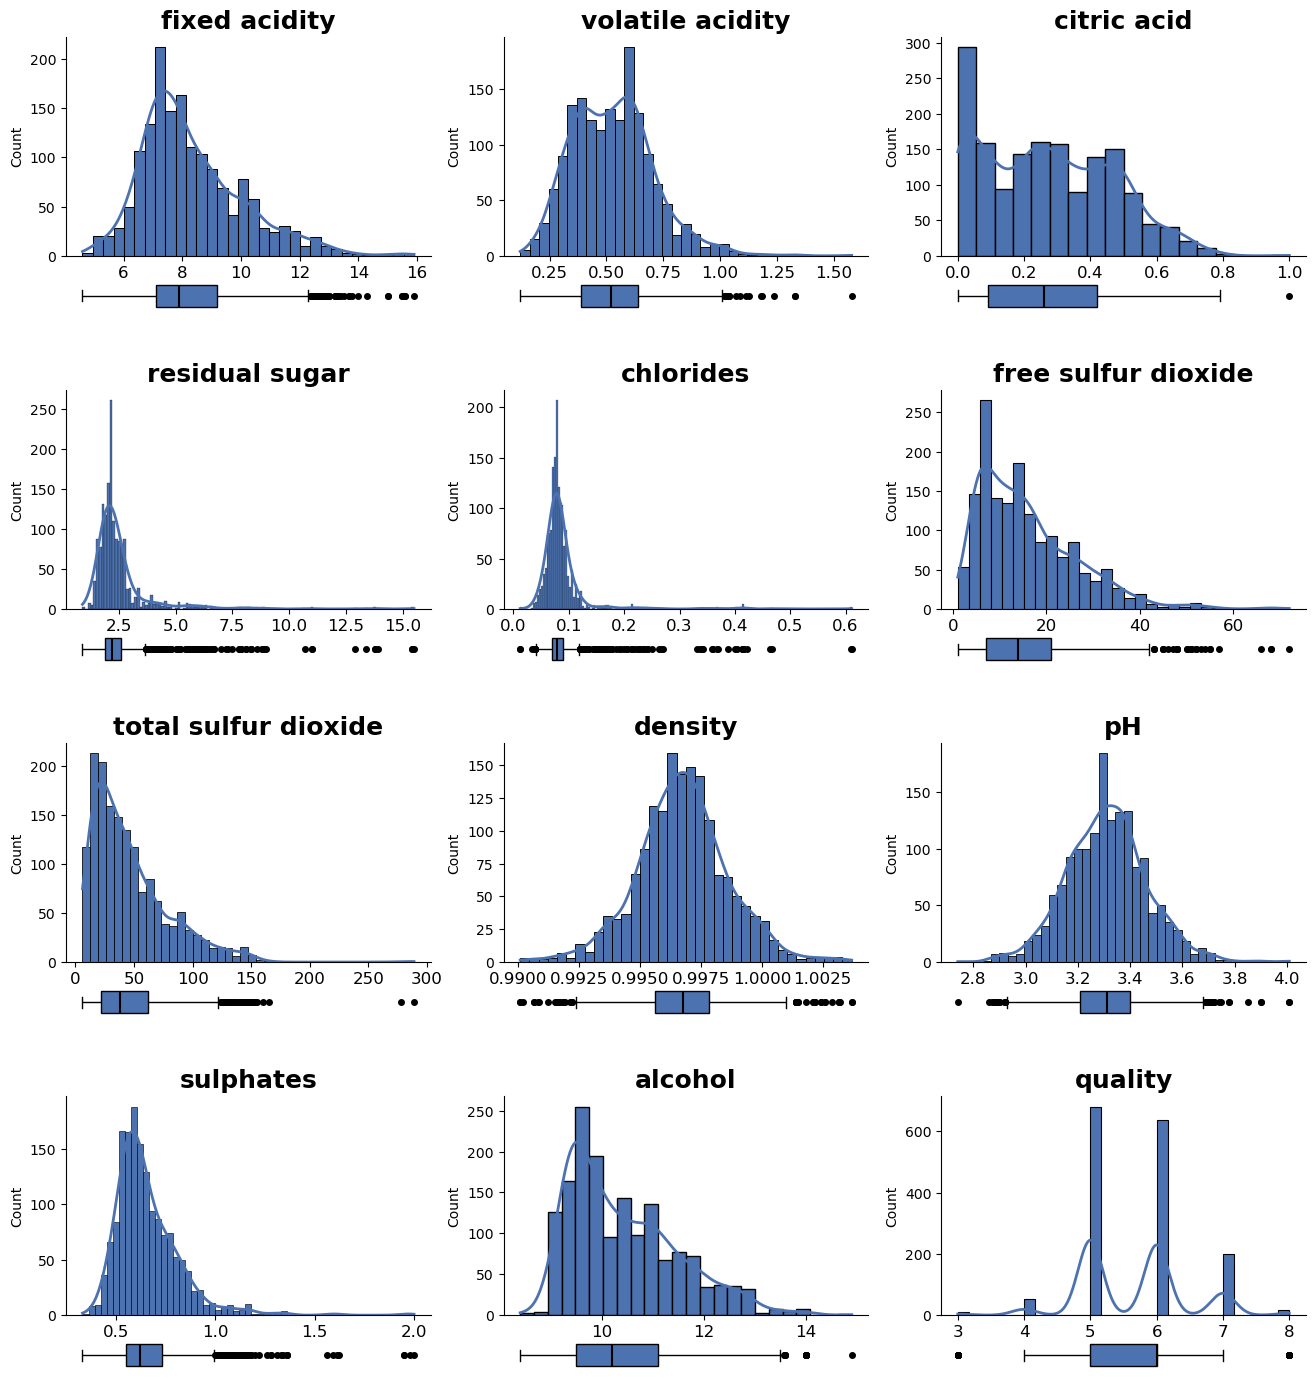

In [6]:
show_histograms(data)

We will normalize features before running regression models. Standard normalization will not change results of correlation and VIF analysis for features.

#### Correlations

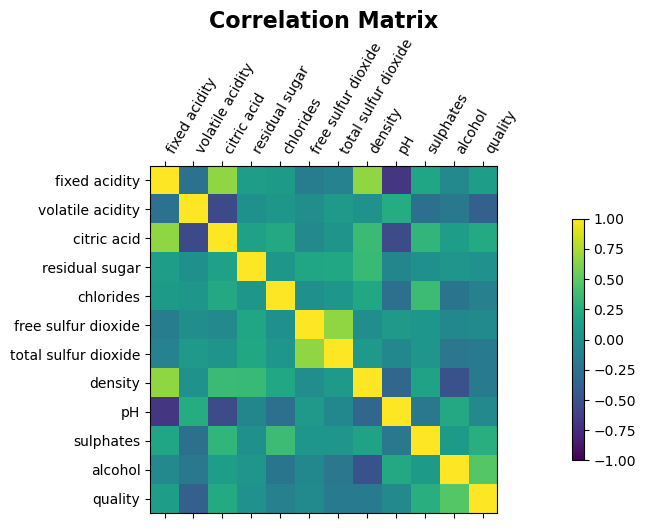

In [7]:
show_correlation_matrix(data)

In [8]:
correlation_analysis(data)

,Feature 1,Feature 2,Correlation,Interpretation
0,fixed acidity,volatile acidity,-0.256131,Weak
1,fixed acidity,citric acid,0.671703,Strong
2,fixed acidity,residual sugar,0.114777,Weak
3,fixed acidity,chlorides,0.093705,Weak
4,fixed acidity,free sulfur dioxide,-0.153794,Weak
5,fixed acidity,total sulfur dioxide,-0.113181,Weak
6,fixed acidity,density,0.668047,Strong
7,fixed acidity,pH,-0.682978,Strong
8,fixed acidity,sulphates,0.183006,Weak
9,fixed acidity,alcohol,-0.061668,Weak


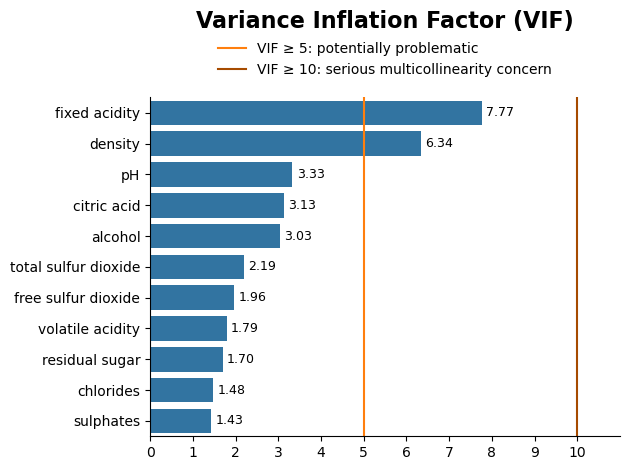

In [9]:
show_VIFs(data)

### Model training

We will run all models with Z-score normalized features

In [10]:
X = data.drop(columns=['quality'])
y = data[['quality']].copy()

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

#### Linear regression

In [11]:
def cross_validate(pipeline):
    r2_scores = cross_val_score(pipeline, X, y, cv=kfold, scoring='r2')

    mse_scores = -cross_val_score(
        pipeline, X, y, cv=kfold, scoring='neg_mean_squared_error'
    )
    mae_scores = -cross_val_score(
        pipeline, X, y, cv=kfold, scoring='neg_mean_absolute_error'
    )

    return {'r2': r2_scores, 'mse': mse_scores, 'mae': mae_scores}


lin_reg_pipeline = Pipeline(
    [('scaler', StandardScaler()), ('regressor', LinearRegression())]
)

lin_reg_scores = cross_validate(lin_reg_pipeline)

print('Performance of linear regression on the test data:\n')
print(
    tabulate(
        [
            ['MSE', lin_reg_scores['mse'].mean(), lin_reg_scores['mse'].std()],
            ['MAE', lin_reg_scores['mae'].mean(), lin_reg_scores['mae'].std()],
            ['R²', lin_reg_scores['r2'].mean(), lin_reg_scores['r2'].std()],
        ],
        headers=['Score', 'Mean', 'Std'],
    )
)

Performance of linear regression on the test data:

Score        Mean        Std
-------  --------  ---------
MSE      0.428763  0.0514309
MAE      0.506955  0.0368316
R²       0.342415  0.0641863


#### Ridge and Lasso regression

* includes tuning of alpha hyperparameter for both models

In [12]:
def tune_paramaters(estimator, cv, parameters):
    pipeline = Pipeline([('scaler', StandardScaler()), ('regressor', estimator)])

    scoring = {
        'r2': 'r2',
        'mse': 'neg_mean_squared_error',
        'mae': 'neg_mean_absolute_error',
    }

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=parameters,
        cv=cv,
        scoring=scoring,
        refit=False,
        n_jobs=-1,
        return_train_score=True,
    )

    grid.fit(X, y)

    results = {}
    param = list(grid.cv_results_['params'][0].keys())[0]
    results[param] = [kv[param] for kv in grid.cv_results_['params']]
    ks = ['mse', 'mae', 'r2']
    for score in ks:
        results[score + ' test'] = (-1 if score != 'r2' else 1) * grid.cv_results_[
            'mean_test_' + score
        ]
    for score in ks:
        results[score + ' train'] = (-1 if score != 'r2' else 1) * grid.cv_results_[
            'mean_train_' + score
        ]

    return pd.DataFrame(results)


ridge = tune_paramaters(Ridge(), kfold, {'regressor__alpha': np.logspace(-5, 5, 100)})
ridge.insert(0, 'Model', 'Ridge')
lasso = tune_paramaters(Lasso(), kfold, {'regressor__alpha': np.logspace(-5, 3, 100)})
lasso.insert(0, 'Model', 'Lasso')

regularization_results = pd.concat([ridge, lasso]).sort_values(
    by=['mse test'], ignore_index=True
)

print('Scoring distributions across all models:')
print(
    regularization_results.describe()
    .loc[['min', '25%', '50%', '75%', 'max']]
    .drop(columns='regressor__alpha')
)

print('\nRidge: 5 best models by MSE')
print(regularization_results[regularization_results['Model'] == 'Ridge'].head(5))

print('\nLasso: 5 best models by MSE')
print(regularization_results[regularization_results['Model'] == 'Lasso'].head(5))

best_ridge_spec = regularization_results[
    regularization_results['Model'] == 'Ridge'
].head(1)[['regressor__alpha']].iloc[0].iloc[0]
best_lasso_spec = regularization_results[
    regularization_results['Model'] == 'Lasso'
].head(1)[['regressor__alpha']].iloc[0].iloc[0]

Scoring distributions across all models:
     mse test  mae test   r2 test  mse train  mae train  r2 train
min  0.427849  0.506955 -0.002309   0.415445   0.499670  0.000000
25%  0.428762  0.506957  0.051056   0.415445   0.499675  0.054469
50%  0.428765  0.507800  0.342410   0.415849   0.500863  0.361981
75%  0.617612  0.663151  0.342415   0.616214   0.661970  0.362600
max  0.652272  0.683509  0.343782   0.651699   0.683090  0.362600

Ridge: 5 best models by MSE
   Model  regressor__alpha  mse test  mae test   r2 test  mse train  \
0  Ridge         73.907220  0.427849  0.508059  0.343782   0.416109   
1  Ridge         93.260335  0.427855  0.508528  0.343762   0.416426   
2  Ridge         58.570208  0.427899  0.507740  0.343713   0.415891   
3  Ridge        117.681195  0.427956  0.509165  0.343595   0.416883   
4  Ridge         46.415888  0.427980  0.507506  0.343596   0.415743   

   mae train  r2 train  
0   0.501538  0.361581  
1   0.502153  0.361094  
2   0.501082  0.361916  
3   0.5

In [13]:
ridge_mse_scores = cross_validate(
    Pipeline(
        [('scaler', StandardScaler()), ('regressor', Ridge(alpha=best_ridge_spec))]
    )
)
lasso_mse_scores = cross_validate(
    Pipeline(
        [('scaler', StandardScaler()), ('regressor', Lasso(alpha=best_lasso_spec))]
    )
)

In [14]:
print(
    tabulate(
        [
            [
                'Linear regression',
                lin_reg_scores['mse'].mean(),
                lin_reg_scores['mae'].mean(),
                lin_reg_scores['r2'].mean(),
            ],
            [
                'Ridge regression (alpha=' + f'{best_ridge_spec:.3f}' + ')',
                ridge_mse_scores['mse'].mean(),
                ridge_mse_scores['mae'].mean(),
                ridge_mse_scores['r2'].mean(),
            ],
            [
                'Lasso regression (alpha=' + f'{best_lasso_spec:.3f}' + ')',
                lasso_mse_scores['mse'].mean(),
                lasso_mse_scores['mae'].mean(),
                lasso_mse_scores['r2'].mean(),
            ],
        ],
        headers=['Model', 'MSE', 'MAE', 'R²'],
    )
)

Model                                 MSE       MAE        R²
-------------------------------  --------  --------  --------
Linear regression                0.428763  0.506955  0.342415
Ridge regression (alpha=73.907)  0.427849  0.508059  0.343782
Lasso regression (alpha=0.012)   0.428148  0.509509  0.343376


#### Random Forest regression

* includes hyperparameter tuning

In [15]:
rf_pipeline = Pipeline(
    [
        ('scaler', StandardScaler()),
        ('regressor', RandomForestRegressor(random_state=42, n_jobs=1)),
    ]
)

rf_params = {
    'regressor__n_estimators': [100, 200, 500],
    'regressor__max_depth': [None, 5, 10, 20],
    'regressor__min_samples_split': [2, 5, 10],
    'regressor__min_samples_leaf': [1, 2, 4],
    'regressor__max_features': [1.0, 'sqrt'],
}

scoring = {
    'r2': 'r2',
    'mse': 'neg_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
}

rf_grid_mse = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    cv=kfold,
    scoring=scoring,
    refit='mse',
    n_jobs=-1,
    return_train_score=True,
)

rf_grid_mse.fit(X, y.values.ravel())

best_rf_mse = rf_grid_mse.best_estimator_

print('Best parameters:', rf_grid_mse.best_params_)

idx = rf_grid_mse.best_index_

print('R2:', rf_grid_mse.cv_results_['mean_test_r2'][idx])
print('MSE:', -rf_grid_mse.cv_results_['mean_test_mse'][idx])
print('MAE:', -rf_grid_mse.cv_results_['mean_test_mae'][idx])

Best parameters: {'regressor__max_depth': 20, 'regressor__max_features': 'sqrt', 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 500}
R2: 0.5057009098833098
MSE: 0.3218697798426099
MAE: 0.41085166408905743


In [16]:
print(
    tabulate(
        [
            [
                'Linear regression',
                lin_reg_scores['mse'].mean(),
                lin_reg_scores['mae'].mean(),
                lin_reg_scores['r2'].mean(),
            ],
            [
                'Ridge regression (alpha=' + f'{best_ridge_spec:.3f}' + ')',
                ridge_mse_scores['mse'].mean(),
                ridge_mse_scores['mae'].mean(),
                ridge_mse_scores['r2'].mean(),
            ],
            [
                'Lasso regression (alpha=' + f'{best_lasso_spec:.3f}' + ')',
                lasso_mse_scores['mse'].mean(),
                lasso_mse_scores['mae'].mean(),
                lasso_mse_scores['r2'].mean(),
            ],
            [
                'Random Forest regression (best parameters)',
                -rf_grid_mse.cv_results_['mean_test_mse'][idx],
                -rf_grid_mse.cv_results_['mean_test_mae'][idx],
                rf_grid_mse.cv_results_['mean_test_r2'][idx],
            ],
        ],
        headers=['Model', 'MSE', 'MAE', 'R²'],
    )
)

Model                                            MSE       MAE        R²
------------------------------------------  --------  --------  --------
Linear regression                           0.428763  0.506955  0.342415
Ridge regression (alpha=73.907)             0.427849  0.508059  0.343782
Lasso regression (alpha=0.012)              0.428148  0.509509  0.343376
Random Forest regression (best parameters)  0.32187   0.410852  0.505701


In [ ]:
Random Forest regression 